<a href="https://colab.research.google.com/github/alyz11/HCI/blob/main/home_credit_default_risk1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Home Credit Default Risk — End-to-End Credit Risk Modeling
**Goal:** estimate the likelihood of payment difficulty (`TARGET = 1`) and evaluate how model thresholds affect the trade-off between risk detection and false positives.

**Dataset available in this workspace:** `application_train.csv` inside `application_train.zip` (307,511 rows, 122 columns). The initial run uses a stratified train/holdout split from the labeled training file. Optional sections at the end load `application_test.csv`, read the column dictionary, audit supporting historical tables, and create test-set predictions/aggregated history features when those files are available.

**Important:** this is an analytical prototype, not a production credit decision system. A model score must not be used as the sole basis for a real lending decision. Validate fairness, calibration, policy compliance, and out-of-time performance before deployment.

## 1. Setup and load data

In [50]:
import os

print("Isi folder /content:")
for item in os.listdir("/content"):
    print(item)

Isi folder /content:
.config
home-credit-default-risk.zip
home-credit-default-risk
.ipynb_checkpoints
sample_data


In [51]:

import os
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, OrdinalEncoder
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, brier_score_loss
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

import zipfile
import os

zip_path = "/content/home-credit-default-risk.zip"
extract_path = "/content/home-credit-default-risk"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Ekstraksi selesai!")
print("Isi folder:", os.listdir(extract_path))

import pandas as pd
from pathlib import Path

# Cari file application_train.csv
matches = list(
    Path("/content/home-credit-default-risk").rglob("application_train.csv")
)

if matches:
    train_path = matches[0]
    df = pd.read_csv(train_path)

    print("Lokasi file:", train_path)
    print("Shape:", df.shape)
    display(df.head())
else:
    print("application_train.csv tidak ditemukan setelah ekstraksi.")


Ekstraksi selesai!
Isi folder: ['installments_payments.csv', 'application_train.csv', 'previous_application.csv', 'sample_submission.csv', 'credit_card_balance.csv', 'application_test.csv', 'HomeCredit_columns_description.csv', 'bureau_balance.csv', 'POS_CASH_balance.csv', 'bureau.csv']
Lokasi file: /content/home-credit-default-risk/application_train.csv
Shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Data quality and target distribution

Duplicate rows: 0
Duplicate SK_ID_CURR: 0


,count,share_pct
TARGET,,
0,282686,91.927118
1,24825,8.072882


,missing_pct
COMMONAREA_AVG,69.872297
COMMONAREA_MODE,69.872297
COMMONAREA_MEDI,69.872297
NONLIVINGAPARTMENTS_MEDI,69.432963
NONLIVINGAPARTMENTS_MODE,69.432963
NONLIVINGAPARTMENTS_AVG,69.432963
FONDKAPREMONT_MODE,68.386172
LIVINGAPARTMENTS_AVG,68.354953
LIVINGAPARTMENTS_MEDI,68.354953
LIVINGAPARTMENTS_MODE,68.354953


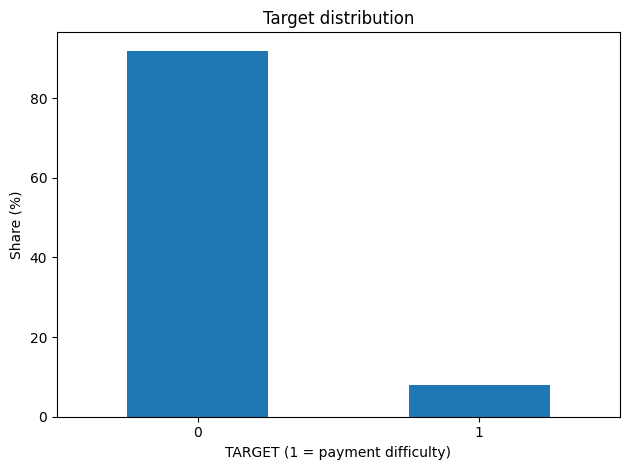

In [52]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate SK_ID_CURR:", df["SK_ID_CURR"].duplicated().sum())
target_summary = df["TARGET"].value_counts().sort_index().rename("count").to_frame()
target_summary["share_pct"] = target_summary["count"] / len(df) * 100
display(target_summary)

missing = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing.head(20).to_frame("missing_pct"))

ax = df["TARGET"].value_counts(normalize=True).sort_index().mul(100).plot(kind="bar", rot=0)
ax.set_title("Target distribution"); ax.set_xlabel("TARGET (1 = payment difficulty)")
ax.set_ylabel("Share (%)"); plt.tight_layout(); plt.show()

## 3. EDA: risk rates by selected segments

In [53]:
def segment_risk(data, col, min_count=100):
    out = data.groupby(col, dropna=False)["TARGET"].agg(["count", "mean"]).reset_index()
    out["target_rate_pct"] = out["mean"] * 100
    return out[out["count"] >= min_count].sort_values("target_rate_pct", ascending=False)

for col in ["NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
            "NAME_FAMILY_STATUS", "FLAG_OWN_CAR", "FLAG_OWN_REALTY"]:
    print("\\n", col)
    display(segment_risk(df, col).head(12))

eda = df[["DAYS_BIRTH","AMT_INCOME_TOTAL","AMT_CREDIT","AMT_ANNUITY","TARGET"]].copy()
eda["AGE_YEARS"] = -eda["DAYS_BIRTH"] / 365.25
eda["AGE_GROUP"] = pd.qcut(eda["AGE_YEARS"], 5, duplicates="drop")
display(eda.groupby("AGE_GROUP", observed=True)["TARGET"].agg(["count","mean"]).assign(target_rate_pct=lambda x: x["mean"]*100))

\n NAME_CONTRACT_TYPE


,NAME_CONTRACT_TYPE,count,mean,target_rate_pct
0,Cash loans,278232,0.083459,8.345913
1,Revolving loans,29279,0.054783,5.478329


\n NAME_INCOME_TYPE


,NAME_INCOME_TYPE,count,mean,target_rate_pct
7,Working,158774,0.095885,9.588472
1,Commercial associate,71617,0.074843,7.484257
4,State servant,21703,0.057550,5.754965
3,Pensioner,55362,0.053864,5.386366


\n NAME_EDUCATION_TYPE


...

\n FLAG_OWN_CAR


,FLAG_OWN_CAR,count,mean,target_rate_pct
0,N,202924,0.085002,8.500227
1,Y,104587,0.072437,7.243730


\n FLAG_OWN_REALTY


,FLAG_OWN_REALTY,count,mean,target_rate_pct
0,N,94199,0.083249,8.324929
1,Y,213312,0.079616,7.961577


,count,mean,target_rate_pct
AGE_GROUP,,,
"(20.503, 32.016]",61512,0.112824,11.282351
"(32.016, 39.469]",61504,0.093295,9.329475
"(39.469, 47.146]",61509,0.078493,7.849258
"(47.146, 56.055]",61491,0.067392,6.739198
"(56.055, 69.073]",61495,0.051630,5.163021


## 4. Data cleaning and feature engineering

In [54]:
data = df.copy()
y = data["TARGET"].astype(int)
X = data.drop(columns=["TARGET", "SK_ID_CURR"]).copy()

# Treat known unknown-category markers as missing where they occur in text columns.
for c in X.select_dtypes(include=["object"]).columns:
    X[c] = X[c].replace(["XNA", "Unknown"], np.nan)

# Convert date-relative fields and add interpretable ratios.
X["AGE_YEARS"] = -X["DAYS_BIRTH"] / 365.25
X["EMPLOYED_YEARS"] = -X["DAYS_EMPLOYED"].where(X["DAYS_EMPLOYED"] != 365243) / 365.25
X["REGISTRATION_YEARS"] = -X["DAYS_REGISTRATION"] / 365.25
X["CREDIT_INCOME_RATIO"] = X["AMT_CREDIT"] / X["AMT_INCOME_TOTAL"].replace(0, np.nan)
X["ANNUITY_INCOME_RATIO"] = X["AMT_ANNUITY"] / X["AMT_INCOME_TOTAL"].replace(0, np.nan)
X["CREDIT_GOODS_RATIO"] = X["AMT_CREDIT"] / X["AMT_GOODS_PRICE"].replace(0, np.nan)
X = X.drop(columns=["DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION"], errors="ignore")

# Remove columns with >65% missingness; threshold is a pragmatic baseline and should be tested.
missing_fraction = X.isna().mean()
drop_high_missing = missing_fraction[missing_fraction > 0.65].index.tolist()
X = X.drop(columns=drop_high_missing)

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]
print("Dropped high-missing columns:", len(drop_high_missing))
print(drop_high_missing)
print("Remaining features:", X.shape[1], "| numeric:", len(numeric_features), "| categorical:", len(categorical_features))

Dropped high-missing columns: 17
['OWN_CAR_AGE', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'FLOORSMIN_AVG', 'LIVINGAPARTMENTS_AVG', 'NONLIVINGAPARTMENTS_AVG', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'FLOORSMIN_MODE', 'LIVINGAPARTMENTS_MODE', 'NONLIVINGAPARTMENTS_MODE', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'FLOORSMIN_MEDI', 'LIVINGAPARTMENTS_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'FONDKAPREMONT_MODE']
Remaining features: 106 | numeric: 91 | categorical: 15


## 5. Split strategy
Keep a stratified 20% holdout for final comparison. To keep the prototype computationally manageable, fit models on a reproducible stratified sample of 50,000 rows from the 80% development partition. The holdout remains separate from model fitting. For a final submission, repeat with a larger training sample and compare stability.

In [55]:
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, _, y_train, _ = train_test_split(
    X_dev, y_dev, train_size=min(50000, len(X_dev)),
    random_state=RANDOM_STATE, stratify=y_dev
)
print("Model-training sample:", X_train.shape, "| Holdout:", X_holdout.shape)
print("Holdout positive rate:", round(y_holdout.mean()*100, 2), "%")

Model-training sample: (50000, 106) | Holdout: (61503, 106)
Holdout positive rate: 8.07 %


## 6. Model 1 — Logistic Regression baseline

In [56]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler(with_mean=False))
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))
])
preprocessor_lr = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

logistic = Pipeline([
    ("prep", preprocessor_lr),
    ("model", LogisticRegression(C=0.1, max_iter=120, class_weight="balanced",
                                 solver="saga", tol=0.002, random_state=RANDOM_STATE))
])
logistic.fit(X_train, y_train)
p_lr = logistic.predict_proba(X_holdout)[:, 1]

## 7. Model 2 — Random Forest baseline

In [57]:
numeric_pipe_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True))
])
categorical_pipe_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])
preprocessor_rf = ColumnTransformer([
    ("num", numeric_pipe_rf, numeric_features),
    ("cat", categorical_pipe_rf, categorical_features)
])
random_forest = Pipeline([
    ("prep", preprocessor_rf),
    ("model", RandomForestClassifier(
        n_estimators=60, max_depth=12, min_samples_leaf=100,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE
    ))
])
random_forest.fit(X_train, y_train)
p_rf = random_forest.predict_proba(X_holdout)[:, 1]

## 8. Hyperparameter tuning (development data only)
The baseline scores below reproduce the initial benchmark configuration. This optional tuning block selects hyperparameters using an internal split of the development sample and does not use the holdout labels. After selecting parameters, refit on the full training sample and evaluate once on the holdout. Run this block if you want the final slides to report tuned-model metrics instead of baseline metrics.

In [58]:
# Lightweight internal tuning example. It may take several minutes depending on runtime.
X_fit, X_tune, y_fit, y_tune = train_test_split(
    X_train, y_train, test_size=0.20, random_state=123, stratify=y_train
)
tuning_rows = []

for C in [0.05, 0.1, 1.0]:
    candidate = Pipeline([
        ("prep", preprocessor_lr),
        ("model", LogisticRegression(C=C, max_iter=120, class_weight="balanced",
                                     solver="saga", tol=0.002, random_state=RANDOM_STATE))
    ])
    candidate.fit(X_fit, y_fit)
    p = candidate.predict_proba(X_tune)[:, 1]
    tuning_rows.append({"model":"Logistic Regression", "C":C, "tuning_roc_auc":roc_auc_score(y_tune,p)})

for depth, leaf in [(10,100), (12,100), (12,60)]:
    candidate = Pipeline([
        ("prep", preprocessor_rf),
        ("model", RandomForestClassifier(n_estimators=40, max_depth=depth, min_samples_leaf=leaf,
                                         max_features="sqrt", class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=RANDOM_STATE))
    ])
    candidate.fit(X_fit, y_fit)
    p = candidate.predict_proba(X_tune)[:, 1]
    tuning_rows.append({"model":"Random Forest", "max_depth":depth, "min_samples_leaf":leaf,
                        "tuning_roc_auc":roc_auc_score(y_tune,p)})

tuning_results = pd.DataFrame(tuning_rows).sort_values("tuning_roc_auc", ascending=False)
display(tuning_results)

,model,C,tuning_roc_auc,max_depth,min_samples_leaf
0,Logistic Regression,0.05,0.753789,NaN,NaN
1,Logistic Regression,0.10,0.753721,NaN,NaN
2,Logistic Regression,1.00,0.753653,NaN,NaN
4,Random Forest,NaN,0.745895,12.0,100.0
5,Random Forest,NaN,0.744286,12.0,60.0
3,Random Forest,NaN,0.743215,10.0,100.0


## 9. Evaluation metrics

,model,threshold,ROC_AUC,PR_AUC,precision,recall,F1,Brier,TN,FP,FN,TP
0,Logistic Regression,0.5,0.747669,0.231218,0.161177,0.676133,0.260303,0.200896,39067,17471,1608,3357
1,Random Forest,0.5,0.740028,0.217579,0.177868,0.576234,0.271829,0.185505,43314,13224,2104,2861


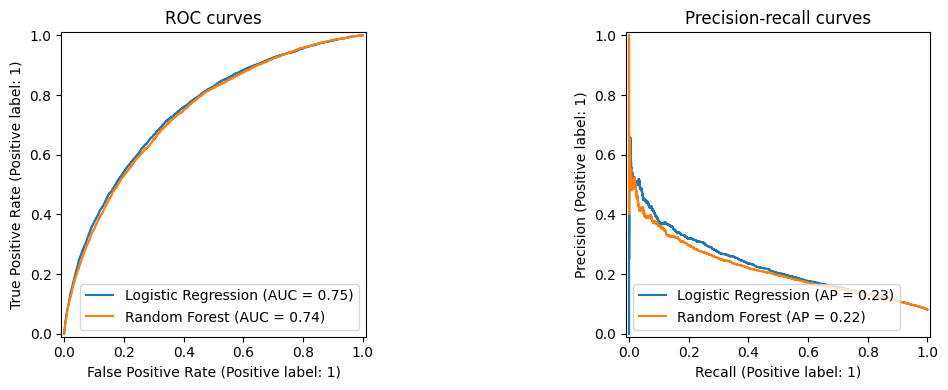

In [59]:
def evaluate(y_true, proba, threshold=0.5, model_name="model"):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {
        "model": model_name, "threshold": threshold,
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Brier": brier_score_loss(y_true, proba),
        "TN":tn, "FP":fp, "FN":fn, "TP":tp
    }

baseline_metrics = pd.DataFrame([
    evaluate(y_holdout, p_lr, 0.5, "Logistic Regression"),
    evaluate(y_holdout, p_rf, 0.5, "Random Forest")
])
display(baseline_metrics)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_holdout, p_lr, name="Logistic Regression", ax=axes[0])
RocCurveDisplay.from_predictions(y_holdout, p_rf, name="Random Forest", ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_holdout, p_lr, name="Logistic Regression", ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_holdout, p_rf, name="Random Forest", ax=axes[1])
axes[0].set_title("ROC curves"); axes[1].set_title("Precision-recall curves")
plt.tight_layout(); plt.show()

## 10. Threshold and business trade-off

In [60]:
# Example: select a threshold on holdout only for exploration. In a formal workflow,
# choose the threshold using a separate validation set, then report once on the test set.
def threshold_metrics(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {"threshold":threshold, "precision":precision_score(y_true,pred,zero_division=0),
            "recall":recall_score(y_true,pred,zero_division=0),
            "F1":f1_score(y_true,pred,zero_division=0),
            "TN":tn,"FP":fp,"FN":fn,"TP":tp}

threshold_table = pd.DataFrame([
    threshold_metrics(y_holdout, p_lr, t) for t in [0.35,0.40,0.45,0.48,0.50,0.55,0.60]
])
display(threshold_table)

,threshold,precision,recall,F1,TN,FP,FN,TP
0,0.35,0.120521,0.857603,0.211341,25466,31072,707,4258
1,0.40,0.132963,0.805438,0.228247,30461,26077,966,3999
2,0.45,0.146425,0.744008,0.244692,35004,21534,1271,3694
3,0.48,0.155778,0.706949,0.255301,37516,19022,1455,3510
4,0.50,0.161177,0.676133,0.260303,39067,17471,1608,3357
5,0.55,0.177021,0.598590,0.273237,42721,13817,1993,2972
6,0.60,0.198998,0.520040,0.287848,46145,10393,2383,2582


## 11. Interpretation and business recommendations

1. **Use risk scores to support review, not automatic rejection alone.** A low threshold catches more risky applicants but increases false positives.
2. **Choose the threshold using explicit business costs.** Estimate the cost of a missed risky applicant (false negative) and the opportunity cost of rejecting a creditworthy applicant (false positive).
3. **Use additional review or tailored offers for borderline cases.** Consider lower principal, shorter/longer maturity, and repayment calendars only after affordability and customer-outcome analysis; do not assume a single schedule suits everyone.
4. **Validate probability calibration and stability.** Brier score, calibration plots, time-based validation, and drift monitoring are important.
5. **Assess fairness and governance.** Review whether sensitive or proxy features create unjustified disparate outcomes. Do not deploy without legal/compliance review and human oversight.

## 12. Export holdout predictions and metric tables

In [61]:
baseline_metrics.to_csv("baseline_model_metrics.csv", index=False)
predictions = pd.DataFrame({
    "TARGET_actual": y_holdout.to_numpy(),
    "probability_logistic": p_lr,
    "probability_random_forest": p_rf
})
predictions.to_csv("holdout_predictions.csv", index=False)
print("Saved baseline_model_metrics.csv and holdout_predictions.csv")

Saved baseline_model_metrics.csv and holdout_predictions.csv


## Limitations
- Only `application_train.csv` was available for this run. `application_test.csv` and the column-description file are still needed for official test predictions and documented feature definitions.
- Baseline training used 50,000 development rows for compute efficiency, while metrics were evaluated on a 61,503-row stratified holdout.
- Random Forest categorical variables use ordinal encoding, which imposes an arbitrary order; consider one-hot encoding or a model with native categorical handling for further work.
- The benchmark metrics are not evidence of causal relationships or production readiness.


---

## 13. Dataset: `application_test.csv`


In [62]:
from pathlib import Path
import pandas as pd

# Folder hasil ekstraksi ZIP
data_dir = Path("/content/home-credit-default-risk")

# Baca deskripsi kolom
columns_path = data_dir / "HomeCredit_columns_description.csv"

if columns_path.exists():
    try:
        columns_description = pd.read_csv(
            columns_path, encoding="utf-8-sig"
        )
    except UnicodeDecodeError:
        columns_description = pd.read_csv(
            columns_path, encoding="latin-1"
        )

    print("Column description loaded:", columns_description.shape)
    display(columns_description.head(10))
else:
    print("File deskripsi kolom tidak ditemukan.")

# Periksa file data test
test_path = data_dir / "application_test.csv"

print(
    "application_test.csv:",
    test_path if test_path.exists() else "BELUM TERSEDIA"
)

Column description loaded: (219, 5)


,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN


application_test.csv: /content/home-credit-default-risk/application_test.csv


## 14. Prediksi pada `application_test.csv`

Model final di bawah dilatih ulang pada seluruh data berlabel untuk memaksimalkan data pembelajaran. Transformasi fitur harus sama persis dengan data training. File prediksi ini bukan bukti performa model karena label test tidak tersedia.


In [63]:
if test_path is not None:
    test_df = pd.read_csv(test_path)
    if 'SK_ID_CURR' not in test_df.columns:
        raise ValueError('application_test.csv harus memiliki kolom SK_ID_CURR')
    test_ids = test_df['SK_ID_CURR'].copy()
    X_test_final = test_df.drop(columns=['SK_ID_CURR']).copy()

    # Apply the same cleaning and feature engineering used for training.
    for c in X_test_final.select_dtypes(include=['object']).columns:
        X_test_final[c] = X_test_final[c].replace(['XNA', 'Unknown'], np.nan)
    X_test_final['AGE_YEARS'] = -X_test_final['DAYS_BIRTH'] / 365.25
    X_test_final['EMPLOYED_YEARS'] = -X_test_final['DAYS_EMPLOYED'].where(X_test_final['DAYS_EMPLOYED'] != 365243) / 365.25
    X_test_final['REGISTRATION_YEARS'] = -X_test_final['DAYS_REGISTRATION'] / 365.25
    X_test_final['CREDIT_INCOME_RATIO'] = X_test_final['AMT_CREDIT'] / X_test_final['AMT_INCOME_TOTAL'].replace(0, np.nan)
    X_test_final['ANNUITY_INCOME_RATIO'] = X_test_final['AMT_ANNUITY'] / X_test_final['AMT_INCOME_TOTAL'].replace(0, np.nan)
    X_test_final['CREDIT_GOODS_RATIO'] = X_test_final['AMT_CREDIT'] / X_test_final['AMT_GOODS_PRICE'].replace(0, np.nan)
    X_test_final = X_test_final.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION'], errors='ignore')
    X_test_final = X_test_final.drop(columns=drop_high_missing, errors='ignore')
    # Match the exact feature columns and order learned from application_train.
    X_test_final = X_test_final.reindex(columns=X.columns)

    from sklearn.base import clone
    submission_model = clone(logistic)
    submission_model.fit(X, y)
    test_probability = submission_model.predict_proba(X_test_final)[:, 1]
    submission = pd.DataFrame({'SK_ID_CURR': test_ids, 'TARGET': test_probability})
    output_path = 'home_credit_predictions.csv'
    submission.to_csv(output_path, index=False)
    print('Predictions saved:', output_path, '| rows:', len(submission))
    display(submission.head())
else:
    print('Lewati prediksi test: letakkan application_test.csv di folder kerja lalu jalankan ulang bagian ini.')


Predictions saved: home_credit_predictions.csv | rows: 48744


,SK_ID_CURR,TARGET
0,100001,0.390421
1,100005,0.675193
2,100013,0.259484
3,100028,0.277220
4,100038,0.636013
